# Capstone Project: Tech Job Salary Prediction 

## i. Project Background
<p style="font-size:18px;">
 TalentPulse Analytics is a global HR technology startup founded in 2020 that provides workforce intelligence and salary benchmarking services to recruitment agencies, enterprise HR teams and job platforms. Operating across the USA, UK, Canada, India and Australia, the company uses data extracted from online job postings to analyse salary trends and skills demand.
 </p>
<p style="font-size:18px;">
The TalentPulse Jobs Dataset comprises 4,653 job postings covering five major technology roles: Data Engineer, Data Scientist, Machine Learning Engineer, Business Analyst and Data Analyst, across Junior, Mid-level, Senior and Lead positions. As competition in the global technology labour market increases, clients require accurate and reliable salary benchmarks to support recruitment and compensation decisions. However, the company's existing lookup-table approach has struggled to capture variations in salaries across job seniority, geographical locations, remote-work arrangements and in-demand technical skills. Consequently, TalentPulse has initiated a machine-learning project to develop a more robust and data-driven salary prediction system.
 </p>

### ii. Business Problem
<p style="font-size:18px;">
TalentPulse Analytics' existing lookup-table salary prediction model records a Mean Absolute Error (MAE) of approximately 18,500 USD, considerably higher than the stated industry benchmark of 8,000 USD. The model also struggles to account for salary differences associated with job seniority, remote-work arrangements and specialised technical skills.
</p>

<p style="font-size:18px;">
Three major limitations have been identified:
 </p>
<p style="font-size:18px;">
1. Seniority effects: The existing model does not adequately capture salary differences between Junior, Mid-level, Senior and Lead positions. The project brief reports that Senior and Lead roles may command a 45–80% salary premium over Mid-level positions.
</p>
<p style="font-size:18px;">
2. Remote-work effects: The relationship between remote-work availability and salary may vary across experience levels, particularly for positions requiring five or more years of experience.
</p>
<p style="font-size:18px;">
3. **Technical skill premiums:** In-demand skills such as Python, Spark and AWS may influence salary levels, but these effects are not adequately represented by job-title-based salary benchmarks.
</p>
<p style="font-size:18px;">
These limitations can result in inaccurate salary estimates, potentially contributing to mispriced job offers, reduced candidate acceptance rates and declining client confidence.
 </p>
<p style="font-size:18px;">
This project therefore investigates the application of machine-learning regression techniques to develop a more accurate and reliable salary prediction model for TalentPulse Analytics.
 </p>
<p style="font-size:18px;">
Three major limitations have been identified:
 </p>
<p style="font-size:18px;">
Seniority effects: The existing model does not adequately capture salary differences between Junior, Mid-level, Senior and Lead positions. The project brief reports that Senior and Lead roles may command a 45–80% salary premium over Mid-level positions.
 </p>
<p style="font-size:18px;">
Remote-work effects: The relationship between remote-work availability and salary may vary across experience levels, particularly for positions requiring five or more years of experience.
 </p>
<p style="font-size:18px;">
Technical skill premiums: In-demand skills such as Python, Spark and AWS may influence salary levels, but these effects are not adequately represented by job-title-based salary benchmarks.
</p>
<p style="font-size:18px;">
These limitations can result in inaccurate salary estimates, potentially contributing to mispriced job offers, reduced candidate acceptance rates and declining client confidence.
</p>
<p style="font-size:18px;">
This project therefore investigates the application of machine-learning regression techniques to develop a more accurate and reliable salary prediction model for TalentPulse Analytics.
 </p>

## 1. Import Library

In [168]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast
import re
import os
from collections import Counter
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings
warnings.filterwarnings("ignore")

## 2. Data Loading and Understanding

In [2]:
data = pd.read_csv("jobs_dataset.csv")
data.shape

(4653, 17)

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4653 entries, 0 to 4652
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   job_id               4653 non-null   int64  
 1   job_title            4653 non-null   object 
 2   company              4652 non-null   object 
 3   location             4653 non-null   object 
 4   salary_min           2299 non-null   float64
 5   salary_max           2295 non-null   float64
 6   description          4653 non-null   object 
 7   country              4653 non-null   object 
 8   search_keyword       4653 non-null   object 
 9   experience_required  487 non-null    float64
 10  degree_required      4653 non-null   object 
 11  skills               4653 non-null   object 
 12  num_skills           4653 non-null   int64  
 13  job_level            4653 non-null   object 
 14  is_remote            4653 non-null   bool   
 15  salary_avg           2299 non-null   f

In [4]:
data.isnull().sum().sort_values(ascending=False)

experience_required    4166
salary_max             2358
salary_avg             2354
salary_min             2354
company                   1
job_id                    0
skills                    0
is_remote                 0
job_level                 0
num_skills                0
search_keyword            0
degree_required           0
job_title                 0
country                   0
description               0
location                  0
has_salary                0
dtype: int64

In [5]:
df = data.copy()  

In [7]:
data.duplicated().sum()

np.int64(0)

In [8]:
data.isnull().sum().sort_values(ascending=False)

experience_required    3887
salary_max             2194
salary_avg             2190
salary_min             2190
company                   1
job_id                    0
skills                    0
is_remote                 0
job_level                 0
num_skills                0
search_keyword            0
degree_required           0
job_title                 0
country                   0
description               0
location                  0
has_salary                0
dtype: int64

In [68]:
data = data.dropna(subset=["salary_avg"]).copy()
data.shape

(2153, 34)

##### Currency conversion into a single country unit

In [56]:
CONVERT_TO_USD = True

fx_rates = {"USA": 1.00, "UK": 1.27, "Canada": 0.73, "Australia": 0.66, "India": 0.012}
data["salary_usd"] = data["salary_avg"] * data["country"].map(fx_rates)     

print(data.groupby("country")["salary_usd"].describe()[["count", "min", "50%", "max"]].round(0))

           count      min       50%       max
country                                      
Australia   94.0      7.0  103125.0  214500.0
Canada     226.0     30.0   80300.0  214985.0
India       62.0      1.0   12600.0   54000.0
UK         913.0  30637.0   63264.0  264160.0
USA        858.0  43449.0  120678.0  368272.0


##### Log transform of the target

In [57]:
print("Skew raw  :", round(data["salary_usd"].skew(), 2))
data["salary_log"] = np.log1p(data["salary_usd"])
print("Skew log  :", round(data["salary_log"].skew(), 2))

Skew raw  : 1.1
Skew log  : -4.66


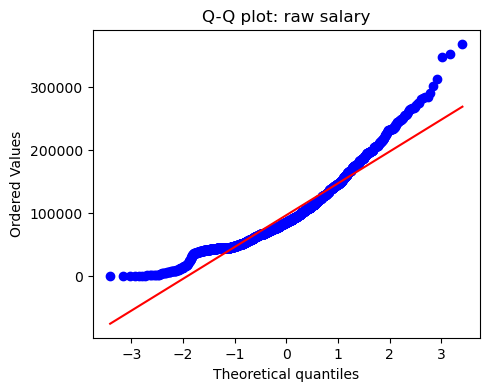

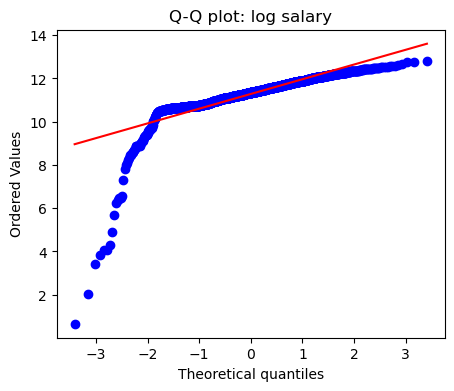

In [58]:
plt.figure(figsize=(5, 4))
stats.probplot(data["salary_usd"], dist="norm", plot=plt)
plt.title("Q-Q plot: raw salary")
plt.show()

plt.figure(figsize=(5, 4))
stats.probplot(data["salary_log"], dist="norm", plot=plt)
plt.title("Q-Q plot: log salary")
plt.show()

## 3.  Exploratory Data Analysis (EDA) and Feature Engineering

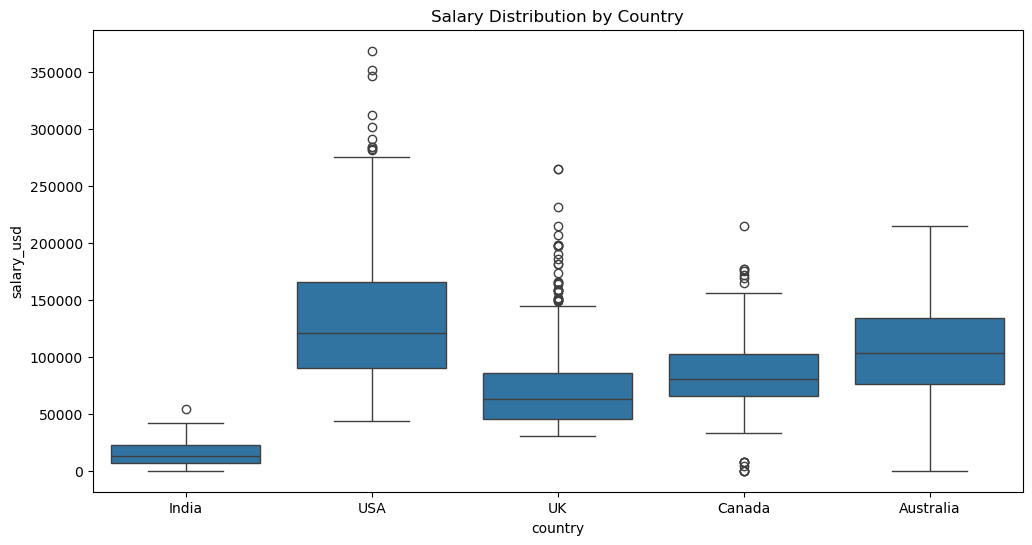

In [60]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=data, x="country", y="salary_usd")
plt.title("Salary Distribution by Country")          
plt.show()

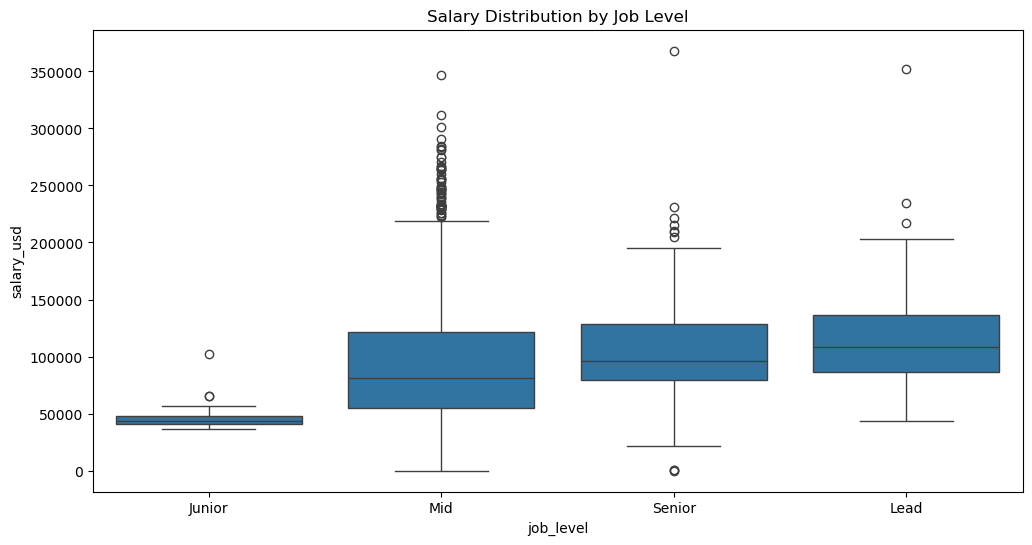

In [61]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=data, x="job_level", y="salary_usd", order=["Junior", "Mid", "Senior", "Lead"])
plt.title("Salary Distribution by Job Level")        
plt.show()

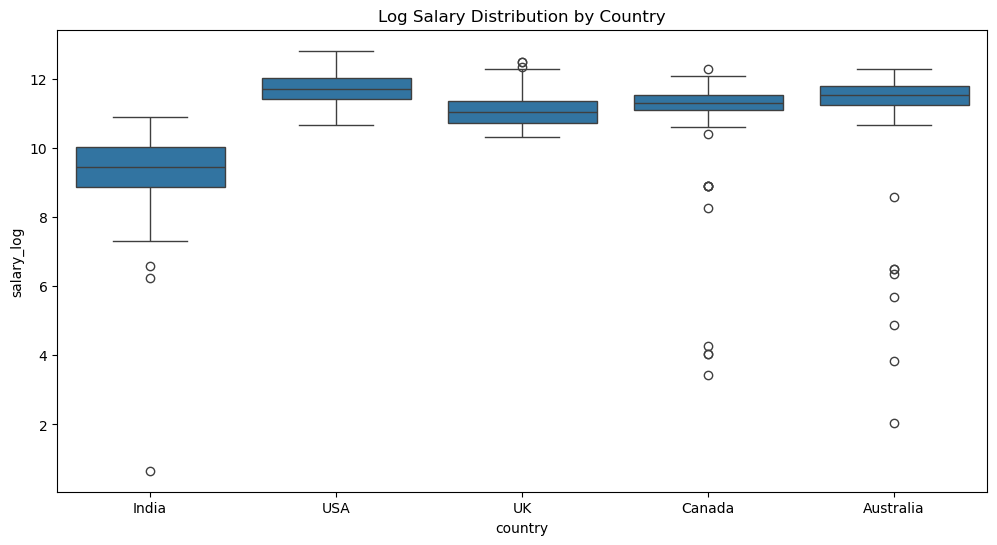

In [62]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=data, x="country", y="salary_log")  
plt.title("Log Salary Distribution by Country")      
plt.show()

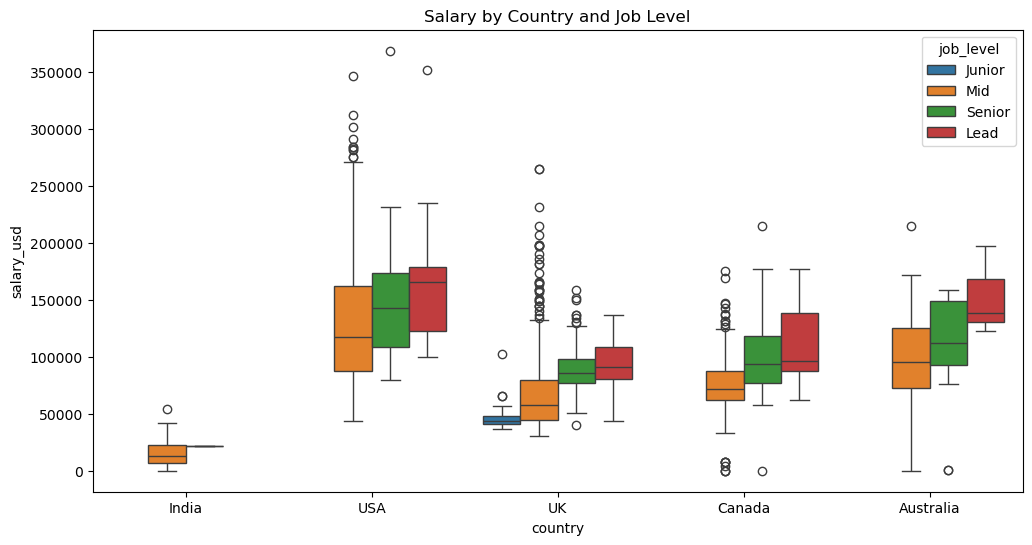

In [63]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=data, x="country", y="salary_usd", hue="job_level", hue_order=["Junior", "Mid", "Senior", "Lead"])
plt.title("Salary by Country and Job Level")
plt.savefig("Salary by country and job level.png", dpi=300, bbox_inches="tight")
plt.show()

In [64]:
# Median salary by country and level, and the Senior / Lead premium over Mid inside each country
medians = data.pivot_table(index="country", columns="job_level", values="salary_usd", aggfunc="median")
counts = data.pivot_table(index="country", columns="job_level", values="salary_usd", aggfunc="count")
print(medians.round(0))
print(counts)
print((medians[["Senior", "Lead"]].div(medians["Mid"], axis=0) - 1).mul(100).round(1))

job_level   Junior      Lead       Mid    Senior
country                                         
Australia      NaN  138600.0   95036.0  112200.0
Canada         NaN   96606.0   71595.0   93258.0
India          NaN       NaN   12600.0   21600.0
UK         43668.0   90948.0   57357.0   85876.0
USA            NaN  165691.0  117269.0  142502.0
job_level  Junior  Lead    Mid  Senior
country                               
Australia     NaN   3.0   72.0    19.0
Canada        NaN  12.0  146.0    68.0
India         NaN   NaN   61.0     1.0
UK           40.0  47.0  724.0   102.0
USA           NaN  28.0  775.0    55.0
job_level  Senior  Lead
country                
Australia    18.1  45.8
Canada       30.3  34.9
India        71.4   NaN
UK           49.7  58.6
USA          21.5  41.3


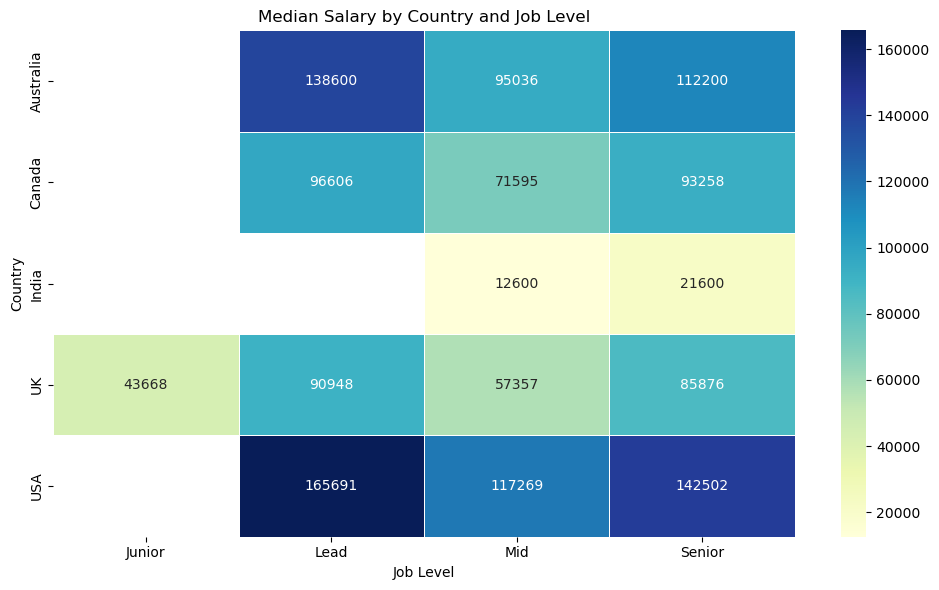

In [20]:
plt.figure(figsize=(10, 6))

sns.heatmap( medians, annot=True, fmt=".0f", cmap="YlGnBu",linewidths=0.5)

plt.title("Median Salary by Country and Job Level")
plt.xlabel("Job Level")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

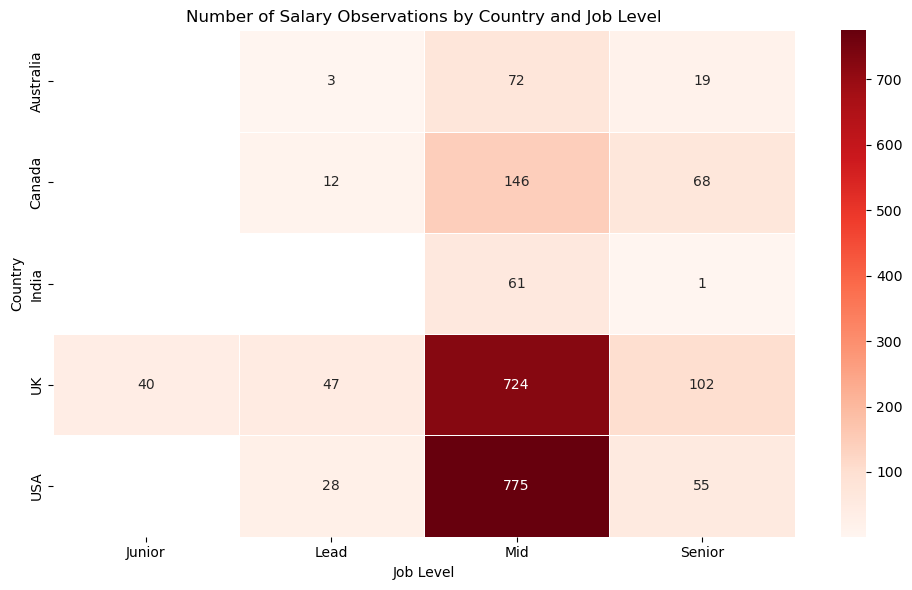

In [65]:
plt.figure(figsize=(10, 6))

sns.heatmap(counts, annot=True, fmt=".0f", cmap="Reds", linewidths=0.5)

plt.title("Number of Salary Observations by Country and Job Level")
plt.xlabel("Job Level")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [66]:
premium = (
    medians[["Senior", "Lead"]]
    .div(medians["Mid"], axis=0)
    .sub(1).mul(100)
)

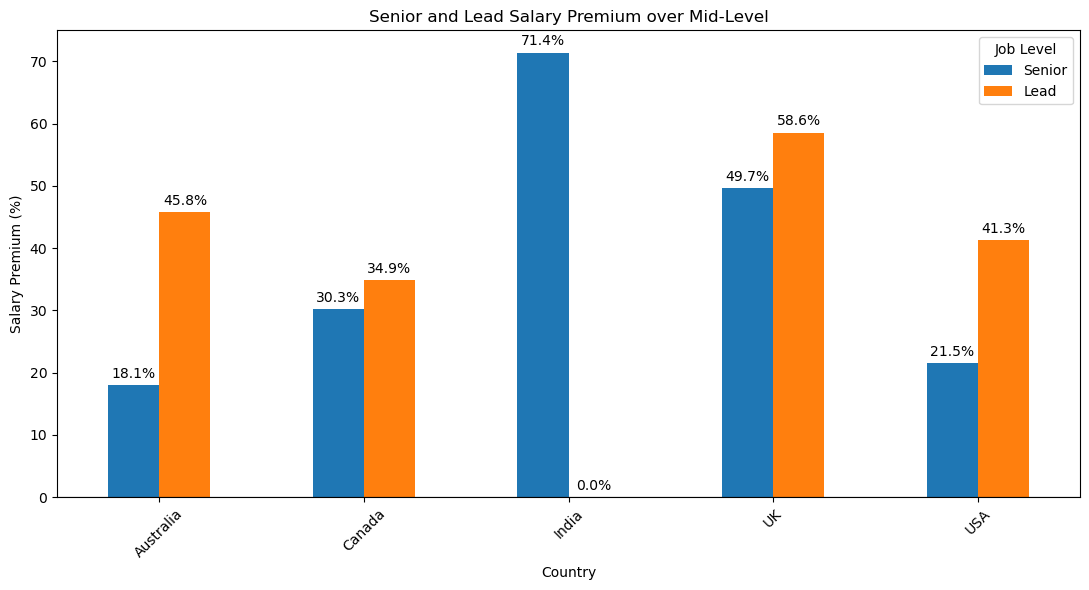

In [67]:
ax = premium.plot(kind="bar", figsize=(11, 6))

ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Senior and Lead Salary Premium over Mid-Level")
ax.set_xlabel("Country")
ax.set_ylabel("Salary Premium (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.xticks(rotation=45)
plt.legend(title="Job Level")
plt.tight_layout()
plt.show()

In [69]:
## Experience
#experience_required is ~97% missing in this subset and has impossible values (up to 200 years).
# 1) treat values outside 0-30 years as missing, 
# 2) keep a flag saying which values were really given,
# 3) fill the rest with the median, 
# 4) build experience_group BEFORE filling so the missing ones become "Unknown".

data["exp_clean"] = data["experience_required"].where(data["experience_required"].between(0, 30))
data["exp_known"] = data["exp_clean"].notna().astype(int)


data["experience_group"] = pd.cut(data["exp_clean"], bins=[-1, 5, 30],
                                  labels=["0-5", "6+"]).astype(object).fillna("Unknown")

data["experience_required"] = data["exp_clean"].fillna(data["exp_clean"].median())
print(data["experience_group"].value_counts())

experience_group
6+     2121
0-5      32
Name: count, dtype: int64


             skills  Counts
0  machine learning     696
1            python     265
2               sql     252
3             excel     183
4               aws      96
5             spark      74
6          power bi      35
7           tableau      21


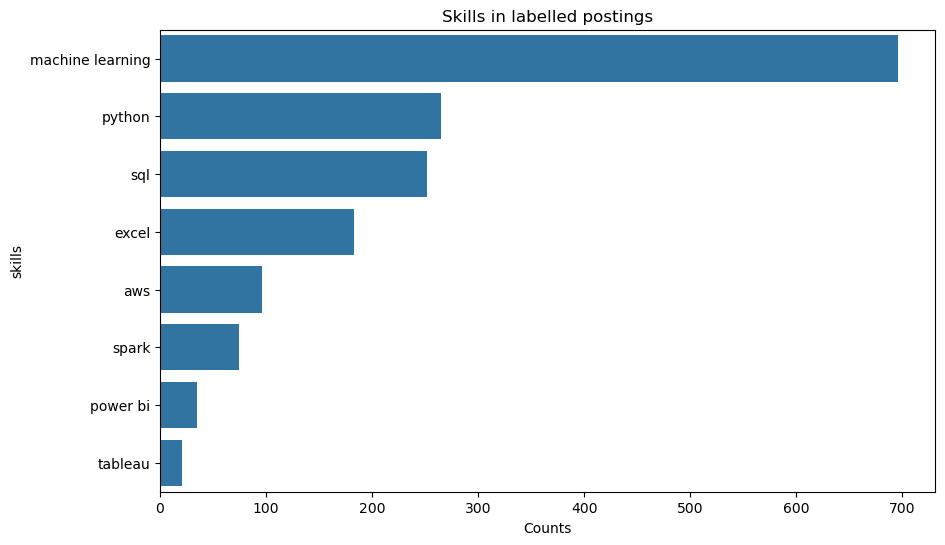

In [31]:
## Process skills


data["skills"] = data["skills"].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else [])

skill_pool = []
for row in data["skills"]:
    skill_pool.extend([s.lower() for s in row])
skill_counts = Counter(skill_pool)

top_skills = pd.DataFrame(skill_counts.most_common(20), columns=["skills", "Counts"])
print(top_skills)

plt.figure(figsize=(10, 6))
sns.barplot(data=top_skills, y="skills", x="Counts")
plt.title("Skills in labelled postings")             
plt.show()

In [32]:
important_skills = ["machine learning", "python", "sql", "excel", "aws", "power bi", "spark", "tableau"]

skill_columns = []
for skill in important_skills:
    col = f"skill_{skill.replace(' ', '_')}"
    data[col] = data["skills"].apply(lambda x: int(any(skill == s.lower() for s in x)))
    skill_columns.append(col)

print(data[skill_columns].sum().sort_values(ascending=False))

skill_machine_learning    696
skill_python              265
skill_sql                 252
skill_excel               183
skill_aws                  96
skill_spark                74
skill_power_bi             35
skill_tableau              21
dtype: int64


In [34]:
## Job title seniority and other features


def title_rank(title):
    t = title.lower()
    if re.search(r"principal|distinguished|director|head|vp|vice president|chief|fellow", t): return 4
    if re.search(r"\blead\b|\bstaff\b|manager", t): return 3
    if re.search(r"senior|\bsr\b", t): return 2
    if re.search(r"intern|trainee|junior|\bjr\b|entry|graduate|associate", t): return 0
    return 1

data["title_rank"] = data["job_title"].apply(title_rank)
data["title_ml"] = data["job_title"].str.lower().str.contains(r"machine learning|\bml\b|\bai\b").astype(int)

data["is_remote"] = data["is_remote"].astype(int)    # 0/1 (one column instead of is_remote_False + is_remote_True)

# is_senior / level group are used for ANALYSIS only (job_level is already a feature)
data["is_senior"] = data["job_level"].isin(["Senior", "Lead"]).astype(int)
data["level_group"] = np.where(data["is_senior"] == 1, "Premium", "Standard")


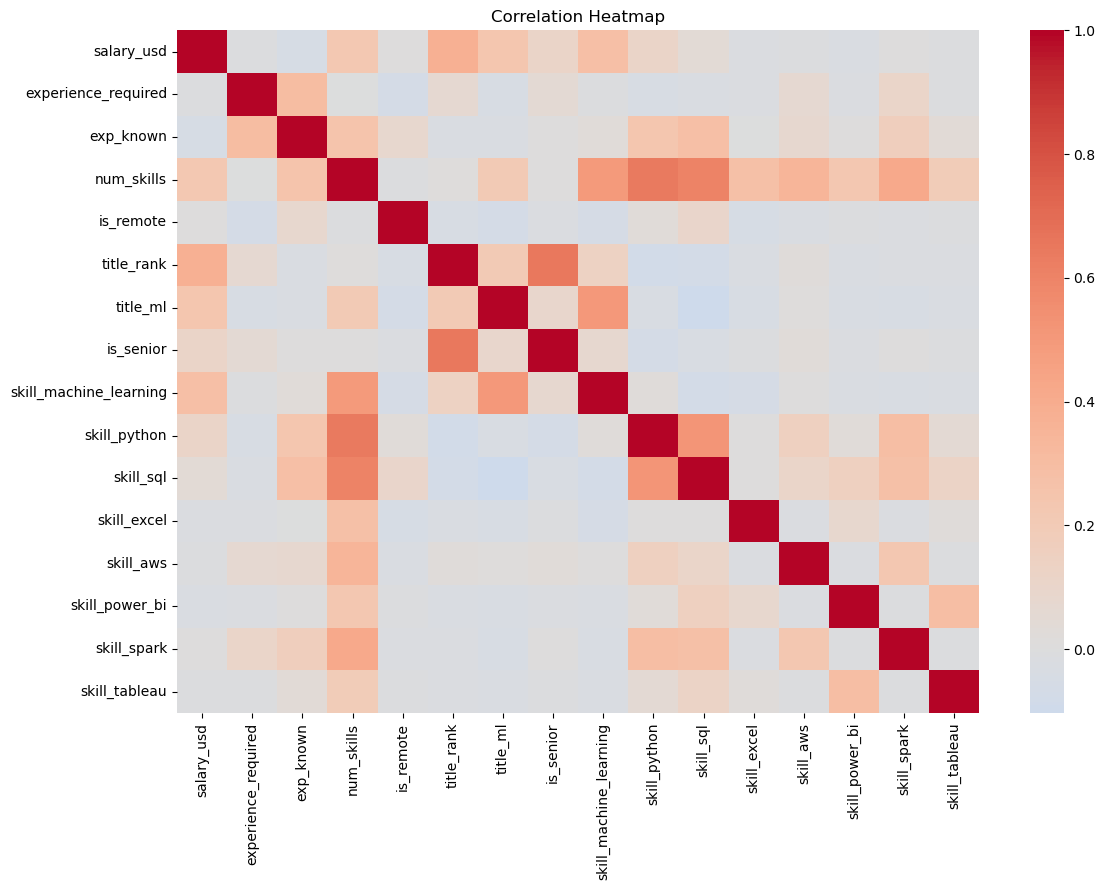

In [35]:
corr_cols = ["salary_usd", "experience_required", "exp_known", "num_skills", "is_remote", "title_rank", "title_ml", "is_senior"] + skill_columns
plt.figure(figsize=(12, 9))
sns.heatmap(data[corr_cols].corr(), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## 4.  Features and target

In [38]:
cat_cols = ["country", "job_level", "search_keyword", "degree_required", "experience_group"]
num_cols = ["experience_required", "exp_known", "num_skills", "is_remote", "title_rank", "title_ml"]

In [44]:
features = cat_cols + num_cols + skill_columns

In [51]:
features

['country',
 'job_level',
 'search_keyword',
 'degree_required',
 'experience_group',
 'experience_required',
 'exp_known',
 'num_skills',
 'is_remote',
 'title_rank',
 'title_ml',
 'skill_machine_learning',
 'skill_python',
 'skill_sql',
 'skill_excel',
 'skill_aws',
 'skill_power_bi',
 'skill_spark',
 'skill_tableau']

In [70]:
X = data[features]
y = data["salary_usd"]          
print(X.shape, y.shape)

(2153, 19) (2153,)


##### Train / test split 80/20

In [71]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=data["country"])
print(X_train.shape, X_test.shape)

(1722, 19) (431, 19)


##### Encoding

In [73]:
encoder = OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)

X_train_encoded = pd.DataFrame(
    encoder.fit_transform(X_train[cat_cols]),
    columns=encoder.get_feature_names_out(),
    index=X_train.index
)

X_test_encoded = pd.DataFrame(
    encoder.transform(X_test[cat_cols]),
    columns=encoder.get_feature_names_out(),
    index=X_test.index
)

X_train = pd.concat([X_train.drop(columns=cat_cols), X_train_encoded], axis=1)
X_test = pd.concat([X_test.drop(columns=cat_cols), X_test_encoded], axis=1)

print(X_train.shape)

(1722, 28)


##### Multicollinearity (VIF)

In [81]:
X_vif = sm.add_constant(X_train.astype(float))

vif = pd.Series(
    [variance_inflation_factor(X_vif.values, i)
     for i in range(X_vif.shape[1])],
    index=X_vif.columns
)

vif = vif.drop("const", errors="ignore")

print(vif[vif > 10].sort_values(ascending=False))

num_skills                                         inf
skill_machine_learning                             inf
skill_python                                       inf
skill_sql                                          inf
skill_excel                                        inf
skill_aws                                          inf
skill_power_bi                                     inf
skill_spark                                        inf
skill_tableau                                      inf
exp_known                                   321.887354
search_keyword_machine learning engineer     12.156196
title_ml                                     11.098818
dtype: float64


In [82]:
print(X_train["exp_known"].value_counts())

exp_known
1    1722
Name: count, dtype: int64


In [83]:
print(X_train.nunique()[X_train.nunique() <= 1])

exp_known    1
dtype: int64


In [84]:
print(X_train["title_ml"].value_counts())

print(pd.crosstab(
    X_train["title_ml"],
    X_train["search_keyword_machine learning engineer"]
))

title_ml
0    1400
1     322
Name: count, dtype: int64
search_keyword_machine learning engineer   0.0  1.0
title_ml                                           
0                                         1392    8
1                                           17  305


In [86]:
drop_cols = ["exp_known", "title_ml"]

In [87]:
X_train = X_train.drop(columns=drop_cols)
X_test = X_test.drop(columns=drop_cols)

##### Scaling

In [89]:
scaler = StandardScaler()
scale_cols = ["experience_required", "title_rank"]
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])      
X_test[scale_cols] = scaler.transform(X_test[scale_cols])

In [90]:
X_train.head()

,experience_required,num_skills,is_remote,title_rank,skill_machine_learning,skill_python,skill_sql,skill_excel,skill_aws,skill_power_bi,...,job_level_Lead,job_level_Mid,job_level_Senior,search_keyword_data analyst,search_keyword_data engineer,search_keyword_data scientist,search_keyword_machine learning engineer,degree_required_Master,degree_required_Not specified,experience_group_6+
976,-0.037388,1,0,-0.315749,1,0,0,0,0,0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0
1185,-0.037388,3,0,-0.315749,0,1,1,1,0,0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0
2422,-0.037388,1,0,0.963592,1,0,0,0,0,0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0
2551,-0.037388,0,0,-0.315749,0,0,0,0,0,0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
1089,-0.037388,0,0,-0.315749,0,0,0,0,0,0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0


## 5. Train the models :  Linear Regression, Random Forest, Gradient  Boosting, and Ridge (Base model) 

In [91]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
}

In [95]:
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2 Score": r2_score(y_test, y_pred)
    })

results = pd.DataFrame(results)
results_df = pd.DataFrame(results).sort_values("MAE").reset_index(drop=True)
print(results_df)


               Model           MAE          RMSE  R2 Score
0      Random Forest  20438.821634  29652.517499  0.666420
1  Gradient Boosting  20774.040764  29194.022891  0.676656
2              Ridge  23177.052389  31901.414465  0.613903
3  Linear Regression  23253.070699  31956.782878  0.612561


### Feature importance

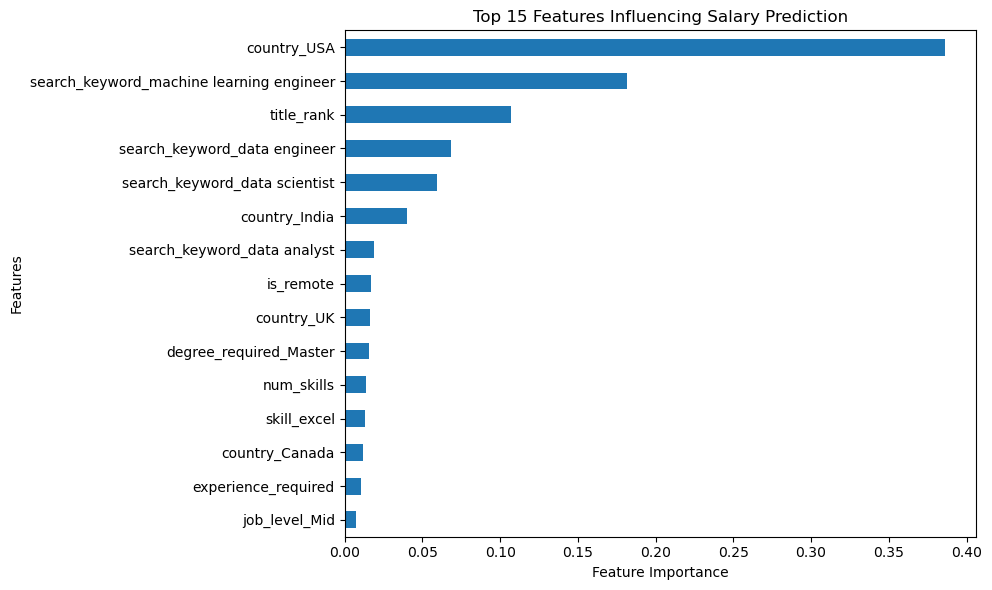

In [113]:

rf_model = models["Random Forest"]

importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False).head(15)

# Plot
importance.sort_values().plot(
    kind="barh", figsize=(10, 6), title="Top 15 Features Influencing Salary Prediction"
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

## 6.  Tune with 5-fold GridSearchCV

In [114]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

models_and_params = {
    "Linear Regression": {"model": LinearRegression(), "params": {"fit_intercept": [True, False]}},

    "Ridge": {"model": Ridge(), "params": {"alpha": [0.01, 0.1, 1, 10, 100, 1000]}},

    "Random Forest": {
        "model": RandomForestRegressor(random_state=42, n_jobs=-1),
        "params": {"n_estimators": [100, 200], "max_depth": [None, 10, 20], "min_samples_leaf": [1, 2]}
    },

    "Gradient Boosting": {
        "model": GradientBoostingRegressor(random_state=42),
        "params": {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "max_depth": [2, 3], "subsample": [0.8, 1.0]}
    }
}

In [115]:
best_models = {}
tuning_results = []

for name, config in models_and_params.items():
    print(f"Tuning {name}...")
    grid_search = GridSearchCV(estimator=config["model"], param_grid=config["params"],
                               scoring="neg_mean_absolute_error",     #
                               cv=cv, n_jobs=-1, refit=True)
    grid_search.fit(X_train, y_train)
    best_models[name] = grid_search.best_estimator_
    tuning_results.append({"Model": name, "Best CV MAE": -grid_search.best_score_,
                           "Best Parameters": grid_search.best_params_})

tuning_results_df = pd.DataFrame(tuning_results).sort_values("Best CV MAE").reset_index(drop=True)
tuning_results_df

Tuning Linear Regression...
Tuning Ridge...
Tuning Random Forest...
Tuning Gradient Boosting...


,Model,Best CV MAE,Best Parameters
0,Random Forest,21497.501834,"{'max_depth': None, 'min_samples_leaf': 2, 'n_..."
1,Gradient Boosting,21886.254207,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti..."
2,Ridge,22973.291141,{'alpha': 0.1}
3,Linear Regression,22974.553407,{'fit_intercept': True}


In [116]:
print("Best Ridge alpha:", best_models["Ridge"].alpha)

Best Ridge alpha: 0.1


In [118]:
best_model_name = tuning_results_df.iloc[0]["Model"]
best_model = best_models[best_model_name]

print("Best model by cross-validation:", best_model_name)

test_results = []

for name, model in best_models.items():
    y_pred = model.predict(X_test)

    test_results.append({
        "Model": name,
        "Test MAE": mean_absolute_error(y_test, y_pred),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "Test R2": r2_score(y_test, y_pred)
    })

test_results_df = pd.DataFrame(test_results).sort_values(
    "Test MAE"
).reset_index(drop=True)

print(test_results_df)

Best model by cross-validation: Random Forest
               Model      Test MAE     Test RMSE   Test R2
0      Random Forest  20483.264667  29589.243848  0.667842
1  Gradient Boosting  21080.886288  29570.297188  0.668267
2              Ridge  23244.246688  31949.322134  0.612742
3  Linear Regression  23253.070699  31956.782878  0.612561


In [120]:
y_pred = best_model.predict(X_test)

best_mae = mean_absolute_error(y_test, y_pred)
best_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
best_r2 = r2_score(y_test, y_pred)

print(f"{best_model_name}: MAE = {best_mae:,.0f} | RMSE = {best_rmse:,.0f} | R2 = {best_r2:.2f}")

print("Legacy model MAE from the brief: 18,500 | Industry benchmark: 8,000")

Random Forest: MAE = 20,483 | RMSE = 29,589 | R2 = 0.67
Legacy model MAE from the brief: 18,500 | Industry benchmark: 8,000


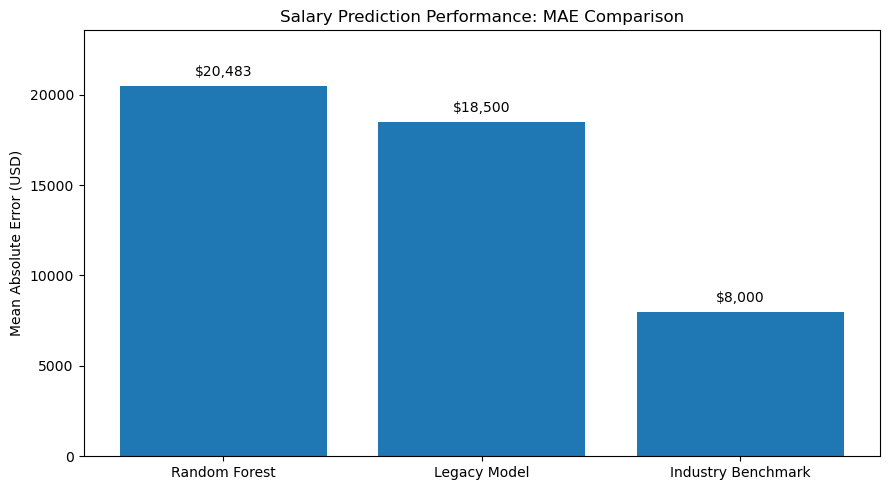

In [148]:
labels = ["Random Forest", "Legacy Model", "Industry Benchmark"]
mae_values = [20483, 18500, 8000]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(labels, mae_values)

ax.set_title("Salary Prediction Performance: MAE Comparison")
ax.set_ylabel("Mean Absolute Error (USD)")

ax.bar_label(bars, labels=[f"${v:,.0f}" for v in mae_values], padding=5)

ax.set_ylim(0, max(mae_values) * 1.15)
plt.tight_layout()
plt.show()

## Random Forest: when does it overfit?

   max_depth  train R2  CV R2    gap
0          3     0.562  0.552  0.010
1          5     0.667  0.627  0.040
2          7     0.706  0.626  0.080
3         10     0.741  0.628  0.113
4         15     0.750  0.626  0.125
5         20     0.750  0.626  0.124


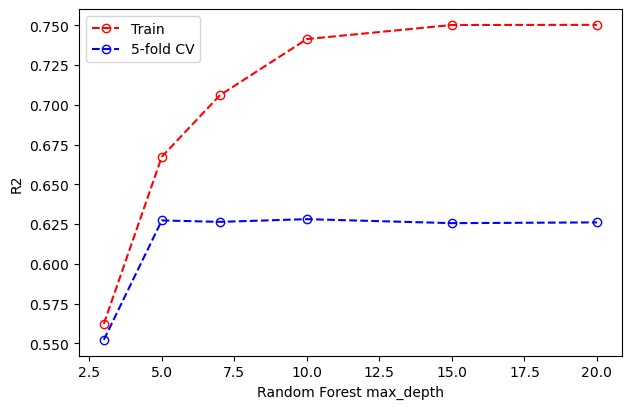

In [126]:
depths = [3, 5, 7, 10, 15, 20]
rf_curve = []
for d in depths:
    rf = RandomForestRegressor(n_estimators=100, max_depth=d, random_state=42, n_jobs=-1)
    cv_score = cross_val_score(rf, X_train, y_train, cv=cv, scoring="r2").mean()
    train_score = rf.fit(X_train, y_train).score(X_train, y_train)
    rf_curve.append({"max_depth": d, "train R2": train_score, "CV R2": cv_score, "gap": train_score - cv_score})
rf_curve_df = pd.DataFrame(rf_curve)
print(rf_curve_df.round(3))

plt.figure(figsize=(7, 4.5))
plt.plot(rf_curve_df["max_depth"], rf_curve_df["train R2"], "--o", label="Train", color="red", mfc="none")
plt.plot(rf_curve_df["max_depth"], rf_curve_df["CV R2"], "--o", label="5-fold CV", color="blue", mfc="none")
plt.xlabel("Random Forest max_depth")
plt.ylabel("R2")
plt.legend()
plt.show()

##### Residual plots

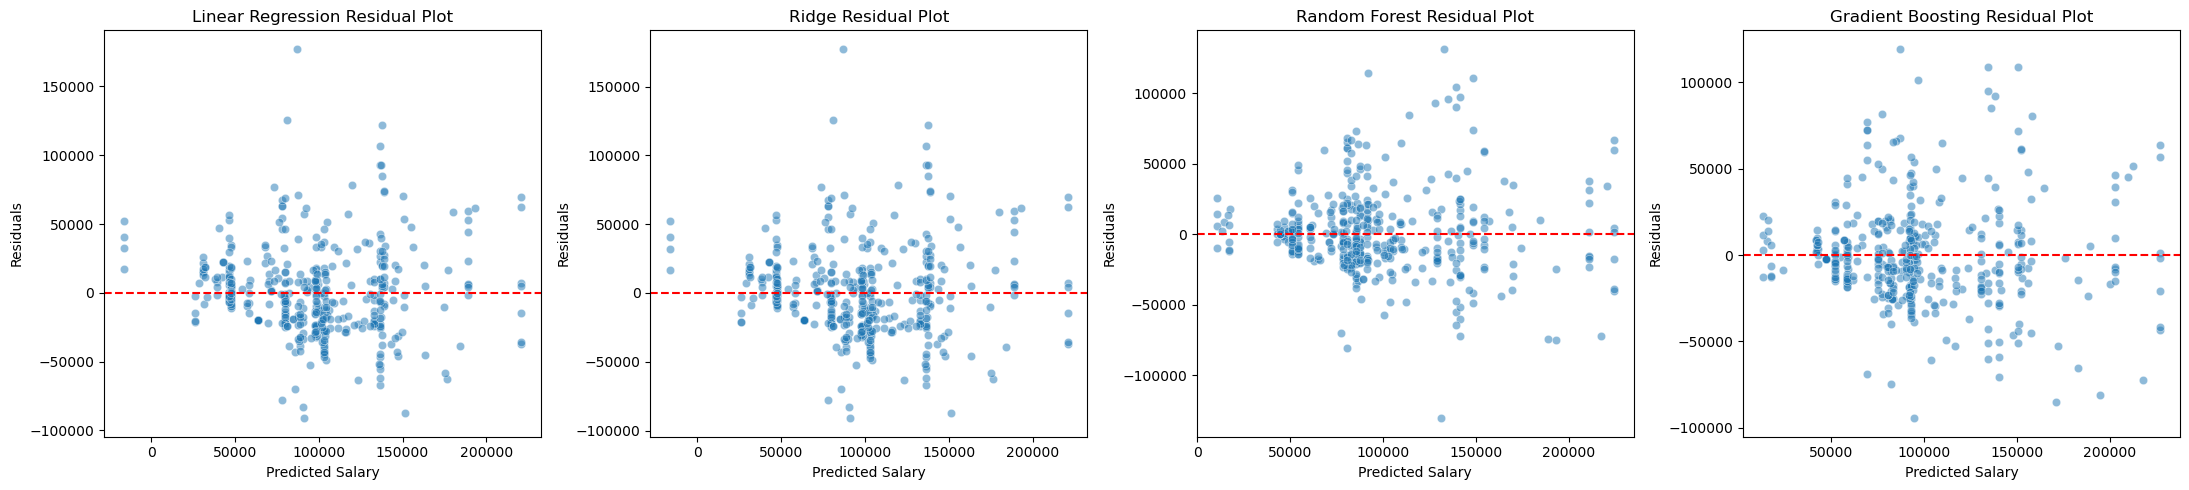

In [128]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5))

for ax, (name, model) in zip(axes, best_models.items()):
    y_pred = model.predict(X_test)
    residuals = y_test - y_pred

    sns.scatterplot(x=y_pred, y=residuals, alpha=0.5, ax=ax)
    ax.axhline(y=0, color="red", linestyle="--")
    ax.set_title(f"{name} Residual Plot")
    ax.set_xlabel("Predicted Salary")
    ax.set_ylabel("Residuals")

plt.tight_layout()
plt.show()

In [129]:
# Residual = actual - predicted
# Positive residual = model underestimates salary

y_pred = best_model.predict(X_test)

residual_df = pd.DataFrame(index=X_test.index)
residual_df["Actual Salary"] = y_test
residual_df["Predicted Salary"] = y_pred
residual_df["Residual"] = y_test - y_pred
residual_df["Residual %"] = residual_df["Residual"] / y_test * 100
residual_df["Abs Error"] = residual_df["Residual"].abs()
residual_df["Country"] = data.loc[X_test.index, "country"]
residual_df["Job Level"] = data.loc[X_test.index, "job_level"]
residual_df["Segment"] = data.loc[X_test.index, "level_group"]

residual_df.head()

,Actual Salary,Predicted Salary,Residual,Residual %,Abs Error,Country,Job Level,Segment
1541,139207.1700,140128.626720,-921.456720,-0.661932,921.456720,USA,Mid,Standard
4328,141559.1100,80722.942701,60836.167299,42.975805,60836.167299,Australia,Mid,Standard
2425,43180.0000,100468.645589,-57288.645589,-132.674029,57288.645589,UK,Mid,Standard
1740,94938.8627,78527.968634,16410.894066,17.285750,16410.894066,UK,Mid,Standard
3183,116800.0000,109404.187599,7395.812401,6.332031,7395.812401,Canada,Mid,Standard


In [130]:
def group_summary(col):
    g = residual_df.groupby(col)
    return pd.DataFrame({"n": g.size(), "mean residual": g["Residual"].mean(), "mean residual %": g["Residual %"].mean(),
                         "MAE": g["Abs Error"].mean()}).round(1)

print("By country:");        print(group_summary("Country"))
print("\nBy job level:");     print(group_summary("Job Level"))
print("\nStandard vs Premium:"); print(group_summary("Segment"))      # FIX 7: Standard vs Premium accuracy
for seg, g in residual_df.groupby("Segment"):
    print(f"R2 {seg}: {r2_score(g['Actual Salary'], g['Predicted Salary']):.2f}")

By country:
             n  mean residual  mean residual %      MAE
Country                                                
Australia   19         7735.3         -11561.0  38108.7
Canada      45           26.1            -23.7  15911.0
India       12         4694.4           -126.3  11180.6
UK         183         1404.0             -5.7  15505.8
USA        172         -989.2             -7.3  25677.4

By job level:
             n  mean residual  mean residual %      MAE
Job Level                                              
Junior       6          789.9              1.3   4006.5
Lead        16         3015.8             -0.6  22831.0
Mid        355          501.7           -508.4  20508.0
Senior      54         1114.4           -815.9  21455.7

Standard vs Premium:
            n  mean residual  mean residual %      MAE
Segment                                               
Premium    70         1549.0           -629.6  21770.0
Standard  361          506.5           -499.9  20233.8
R2 

In [131]:
def group_summary(col):
    g = residual_df.groupby(col)

    return pd.DataFrame({
        "n": g.size(),
        "Mean Residual": g["Residual"].mean(),
        "Mean Residual %": g["Residual %"].mean(),
        "MAE": g["Abs Error"].mean()
    }).round(1)

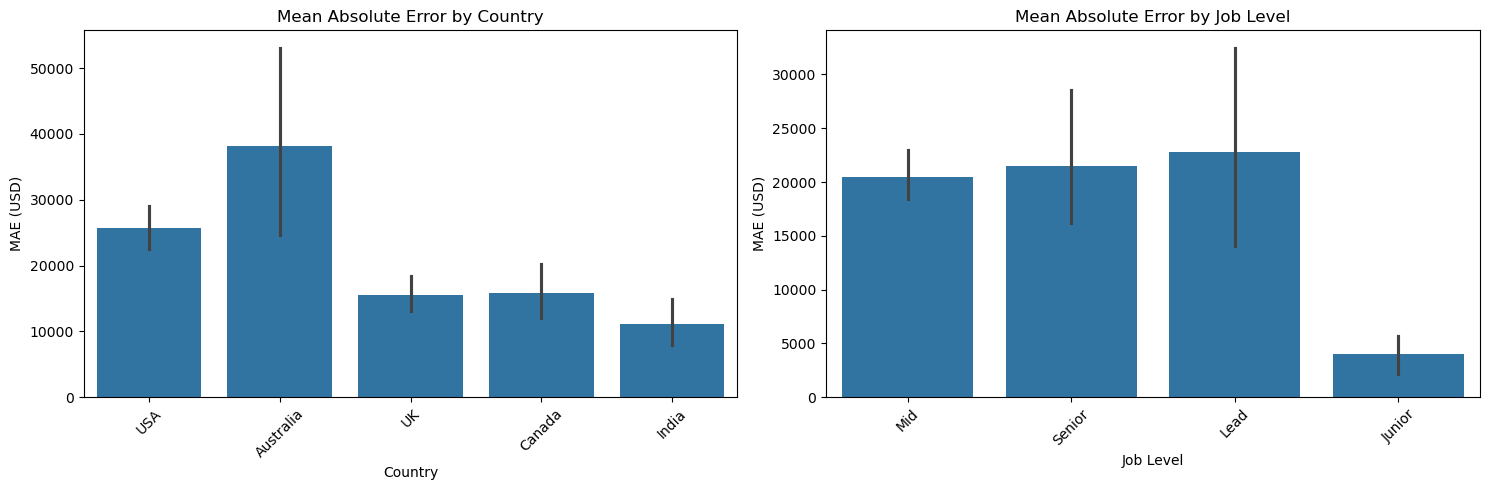

In [132]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(data=residual_df, x="Country", y="Abs Error", ax=axes[0], estimator="mean")
axes[0].set_title("Mean Absolute Error by Country")
axes[0].set_ylabel("MAE (USD)")
axes[0].tick_params(axis="x", rotation=45)

sns.barplot(data=residual_df, x="Job Level", y="Abs Error", ax=axes[1], estimator="mean")
axes[1].set_title("Mean Absolute Error by Job Level")
axes[1].set_ylabel("MAE (USD)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

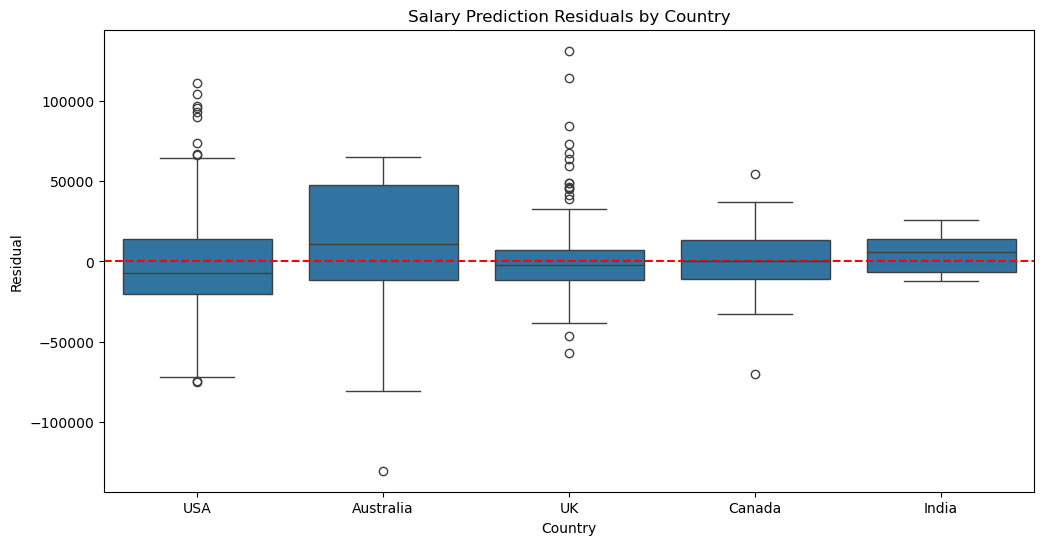

In [133]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=residual_df, x="Country", y="Residual")
plt.axhline(0, color="red", linestyle="--")
plt.title("Salary Prediction Residuals by Country")
plt.show()


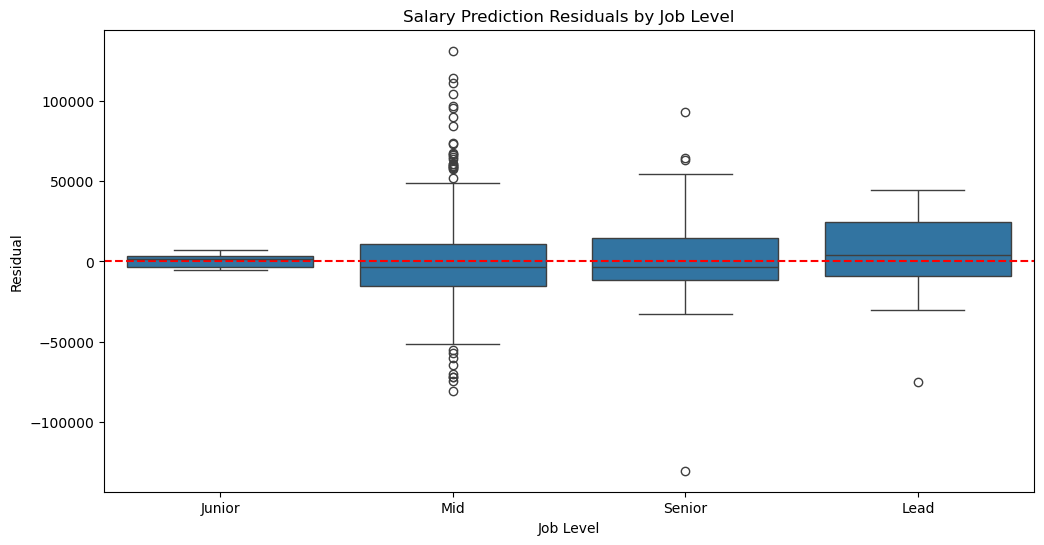

In [134]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=residual_df, x="Job Level", y="Residual", order=["Junior", "Mid", "Senior", "Lead"])
plt.axhline(0, color="red", linestyle="--")
plt.title("Salary Prediction Residuals by Job Level")
plt.show()

## 7. Model Deployment

In [144]:
%%capture
%pip install gradio -q

In [146]:
import joblib

In [147]:
joblib.dump(best_model, "salary_model.pkl")
joblib.dump(encoder, "salary_encoder.pkl")
joblib.dump(X_train.columns.tolist(), "model_columns.pkl")

print("Model files saved successfully!")

Model files saved successfully!


In [149]:
model = joblib.load("salary_model.pkl")
encoder = joblib.load("salary_encoder.pkl")
model_columns = joblib.load("model_columns.pkl")

print("Model loaded:", type(model).__name__)
print("Encoder loaded:", type(encoder).__name__)
print("Number of model features:", len(model_columns))

Model loaded: RandomForestRegressor
Encoder loaded: OneHotEncoder
Number of model features: 26


In [160]:
import gradio as gr

In [161]:
print(gr.__version__)

6.32.0


In [169]:
# Calculate job title seniority
def calculate_title_rank(title):
    t = title.lower()

    if re.search(r"principal|distinguished|director|head|vp|vice president|chief|fellow", t):
        return 4
    if re.search(r"\blead\b|\bstaff\b|manager", t):
        return 3
    if re.search(r"senior|\bsr\b", t):
        return 2
    if re.search(r"intern|trainee|junior|\bjr\b|entry|graduate|associate", t):
        return 0

    return 1


# Connect user inputs to the trained model
def predict_salary(
    job_title, job_category, country, job_level,
    experience, education, remote, num_skills,
    machine_learning, python, sql, excel,
    aws, power_bi, spark, tableau
):

    if not job_title or not job_category or not country or not job_level or not education:
        raise gr.Error("Please complete all job information.")

    if experience is None or experience < 0:
        raise gr.Error("Please enter valid years of experience.")

    if num_skills is None or num_skills < 0:
        raise gr.Error("Please enter a valid number of skills.")

    # Categorical inputs
    categorical_input = pd.DataFrame([{
        "country": country,
        "job_level": job_level,
        "search_keyword": job_category,
        "degree_required": education,
        "experience_group": "6+" if experience > 5 else "0-5"
    }])

    # Encode categorical features
    encoded = encoder.transform(categorical_input)

    if hasattr(encoded, "toarray"):
        encoded = encoded.toarray()

    encoded_df = pd.DataFrame(
        encoded,
        columns=encoder.get_feature_names_out()
    )

    # Numerical and binary features
    numeric_df = pd.DataFrame([{
        "experience_required": experience,
        "num_skills": num_skills,
        "is_remote": int(remote),
        "title_rank": calculate_title_rank(job_title),
        "skill_machine_learning": int(machine_learning),
        "skill_python": int(python),
        "skill_sql": int(sql),
        "skill_excel": int(excel),
        "skill_aws": int(aws),
        "skill_power_bi": int(power_bi),
        "skill_spark": int(spark),
        "skill_tableau": int(tableau)
    }])

    # Combine and arrange the exact 26 model features
    input_data = pd.concat([numeric_df, encoded_df], axis=1)
    input_data = input_data.reindex(columns=model_columns, fill_value=0)

    # Predict salary
    prediction = model.predict(input_data)[0]

    return f"Predicted Annual Salary: ${prediction:,.2f} USD"


# Build Gradio interface
with gr.Blocks(title="TalentPulse Analytics") as demo:

    gr.Markdown("# TalentPulse Analytics")
    gr.Markdown("### Global Salary Prediction")

    with gr.Row():
        job_title = gr.Textbox(label="Full Job Title",
                               placeholder="e.g. Senior Data Scientist")
        job_category = gr.Dropdown(
            ["business analyst", "data analyst", "data engineer",
             "data scientist", "machine learning engineer"],
            label="Job Category"
        )

    with gr.Row():
        country = gr.Dropdown(
            ["Australia", "Canada", "India", "UK", "USA"],
            label="Country"
        )
        job_level = gr.Dropdown(
            ["Junior", "Mid", "Senior", "Lead"],
            label="Job Level"
        )

    with gr.Row():
        experience = gr.Number(label="Years of Experience", value=3)
        education = gr.Dropdown(
            ["Bachelor", "Master", "Not specified"],
            label="Education"
        )

    remote = gr.Radio([0, 1], value=0, label="Remote Work (0 = No, 1 = Yes)")
    num_skills = gr.Number(label="Total Number of Skills", value=3)

    gr.Markdown("### Select Your Skills")

    with gr.Row():
        machine_learning = gr.Checkbox(label="Machine Learning")
        python = gr.Checkbox(label="Python")
        sql = gr.Checkbox(label="SQL")
        excel = gr.Checkbox(label="Excel")

    with gr.Row():
        aws = gr.Checkbox(label="AWS")
        power_bi = gr.Checkbox(label="Power BI")
        spark = gr.Checkbox(label="Spark")
        tableau = gr.Checkbox(label="Tableau")

    button = gr.Button("Predict Salary", variant="primary")
    result = gr.Textbox(label="Salary Prediction")

    button.click(
        predict_salary,
        inputs=[
            job_title, job_category, country, job_level,
            experience, education, remote, num_skills,
            machine_learning, python, sql, excel,
            aws, power_bi, spark, tableau
        ],
        outputs=result
    )



demo.launch(
    server_name="0.0.0.0",
    server_port=int(os.environ.get("PORT", 10000))
)
#demo.launch()


* Running on local URL:  http://0.0.0.0:10000
* To create a public link, set `share=True` in `launch()`.
